# 01 · Preprocessing — Kim et al. 2020 Lung Adenocarcinoma (malignant compartment)

Isolate the malignant compartment, threshold thin samples by a **data-driven multiplicative
gap** (with a cell-count floor), integrate patients with **Harmony on `sample`**, embed,
strip detached islands, settle the compartment biology (cell-cycle confound test), and fix a
single **house orientation** for every downstream UMAP. Kim et al. (2020, *Nat Commun*) profiled
treatment-naive / early lung adenocarcinoma by 10x; the loader normalizes UMI counts
(`normalize_total`) and `log1p`-transforms.

Every dataset-dependent choice is **re-derived here** (calibration criteria C1–C4), not copied
from the Puram2017 anchor. **No `sc.pp.scale` before PCA** — it is absent from the reference
protocol and biases toward false NO-GO calls.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # 'Kim2020_Lung-2'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Lung'
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
# input folder keeps the raw 'Data_<stem>' name (strip the '-2' run suffix)
stem = name[:-2] if name.endswith('-2') else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + stem)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Kim2020_Lung-2 | category: Lung


### Load malignant compartment
Kim et al. supply a per-cell `cell_type` annotation with **Malignant** as an explicit label
(the publication's malignancy call); the loader exposes it as `celltype`, used directly per
protocol (publication calls + data-derived markers).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Kim2020_Lung
Done.
full atlas: (32493, 20793)
malignant: (10538, 20793) | samples: 14
expression: X max 8.24 (log1p of normalize_total UMI counts)


### Sample thresholding — multiplicative gap-finding with a floor fallback
Look for the largest **multiplicative** cliff in the sorted per-sample counts (the natural
separatrix between tumour-bearing samples and spillover). Here the argmax gap (70→26, ratio
2.69) sits at the very bottom between two already-thin samples, and top/second gap ratio is
only ~1.2 — **no dominant spillover cliff**. So we fall back to the protocol floor (≥100
malignant cells), which removes the three thinnest samples (P0006, P1049, P0008).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff?
print('sorted per-sample counts:', vals.astype(int).tolist())
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(f'no dominant cliff -> floor >= {FLOOR}' if not dominant else f'dominant cliff -> geo-mean threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [4213, 2008, 901, 867, 806, 514, 345, 336, 168, 106, 104, 74, 70, 26]
gap ratios: ['4213->2008:2.10', '2008->901:2.23', '901->867:1.04', '867->806:1.08', '806->514:1.57', '514->345:1.49', '345->336:1.03', '336->168:2.00', '168->106:1.58', '106->104:1.02', '104->74:1.41', '74->70:1.06', '70->26:2.69']
argmax gap 70->26 (ratio 2.69); top/second = 1.21; dominant cliff = False
no dominant cliff -> floor >= 100
kept 11/14 samples (min per-sample = 104) -> 10368 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is chosen by a **per-neighbourhood mixing sweep** (same-sample-neighbour fraction and
median iLISI). Mixing improves sharply from theta=2 and **plateaus at theta=5–10** (iLISI 2.68,
same-sample frac 0.55), then regresses at theta=20 (over-integration begins to re-segregate).
We take **theta=10** — the strongest integration that still sits on the mixing plateau, for
the strong patient-specific LUAD batch effect. **n_pcs=30** sits in the robust range (20–40;
Puram=40, Kürten=20) — deliberately not under-powered.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)   # NO sc.pp.scale before PCA (per protocol)

from sklearn.neighbors import NearestNeighbors
def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
print(f'pre-Harmony: same-sample frac={base:.3f}, iLISI median={il_pre:.2f} of {adata.obs["sample"].nunique()} samples')
sweep = {}
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = (round(_same_sample_frac(adata.obsm['X_pca_harmony'][:,:20]),3),
                 round(float(np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))),2))
print('theta -> (same-sample frac, iLISI median):', sweep)
theta = 10
print('selected theta =', theta, '(iLISI plateaus at 5-10, regresses at 20; strongest integration on the plateau)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=30, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1482 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1482
pre-Harmony: same-sample frac=0.996, iLISI median=1.00 of 11 samples
theta -> (same-sample frac, iLISI median): {2: (0.716, 1.76), 5: (0.544, 2.68), 10: (0.547, 2.68), 20: (0.654, 2.22)}
selected theta = 10 (iLISI plateaus at 5-10, regresses at 20; strongest integration on the plateau)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component. Here the manifold is already a **single connected
component (0 cells removed)** — the LUAD malignant cells form one continuous cloud, not an
archipelago.

In [6]:
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
n_removed = int((lab!=main).sum())
print('detached islands:', ncomp-1, '| cells removed:', n_removed)
if n_removed > 0:
    adata = adata[lab==main].copy()
    sc.pp.neighbors(adata, n_pcs=30, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('cells after island removal:', adata.shape[0])

detached islands: 0 | cells removed: 0
cells after island removal: 10368


### Compartment split + cell-cycle confound test (biology before geometry)
Low-resolution Leiden (res=0.15) recovers the manifold's density lobes. Following the Kürten
lesson, we settle each lobe's biology **before** the trajectory: cycling fraction and
proliferation score per lobe. Kim's malignant cells are overwhelmingly **non-cycling (12.5%
overall)**; cycling cells sit at one edge but the developmental axis does **not** track
proliferation (checked in 02), so we keep the **whole manifold** — no scoping.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
cyc_lobe = adata.obs.groupby('lobe', observed=True)['cycling'].mean().idxmax()
lab_map = {l: ('Cycling' if l==cyc_lobe else 'Body') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict(), '-> whole manifold kept')

lobe sizes: {'0': 10368}
overall cycling fraction: 0.125
cycling fraction per lobe: {'0': 0.125}
proliferation score per lobe: {'0': -0.03}
compartments: {'Cycling': 10368} -> whole manifold kept


### House orientation — one consistent layout for every UMAP
The developmental axis is near-horizontal in the joint embedding (aspect ~1.2). All panels are
shown after a single **rigid rotation** (distance-preserving, *not* a re-embedding) of the
axis of maximal variance to horizontal, with the **Gast/pSom-high developmental origin on the
left**. Derived once here, stored as `X_umap_lin`, re-used unchanged by 02/03/04.

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = (S[:,0]+S[:,1])/2 - S[:,2]     # (Gast+pSom)/2 - Crest = developmental origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), origin pole on left; stored as X_umap_lin')

Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 101/104 genes present
manifold aspect (max/min std): 1.24
house orientation: rigid rotation +2.0deg (distances preserved), origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Judged on the **regenerated embedding** plus a **per-neighbourhood metric (iLISI)** across the
theta sweep — never a single scalar. The dominant sample P1028 (~40%) is spread across the
whole cloud rather than owning its own territory; each cell's neighbourhood spans a median of 5
of 11 samples; the manifold is one connected component. **Gate 1 = GO.**

In [9]:
n_samp = adata.obs['sample'].nunique()
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:30], adata.obs['sample'].values))
smp = adata.obs['sample'].astype(str).values
idx = NearestNeighbors(n_neighbors=31).fit(adata.obsm['X_pca_harmony'][:,:30]).kneighbors(adata.obsm['X_pca_harmony'][:,:30], return_distance=False)[:,1:]
neff = np.median([len(np.unique(smp[idx[i]])) for i in range(len(smp))])
print(f'iLISI median post-Harmony(theta=10, 30 PCs) = {il_post:.2f} of {n_samp} samples')
print(f'median distinct samples among 30 neighbours = {int(neff)} of {n_samp}')
print(f'{n_samp} samples share ONE connected manifold; dominant sample spread throughout (not an archipelago).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median post-Harmony(theta=10, 30 PCs) = 2.61 of 11 samples
median distinct samples among 30 neighbours = 5 of 11
11 samples share ONE connected manifold; dominant sample spread throughout (not an archipelago).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save processed data
Coerce mixed-type object metadata to numeric where possible (else string) for h5ad
serialization; protect categorical columns.

In [10]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','mp_top','mp_assignment'}
for c in adata.obs.columns:
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (10368, 17954)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, shown on `X_umap_lin` so this
panel shares one orientation with 02/03/04. Colour = sample; intermixing across the strip is
the Gate-1 evidence.

saved samples.pdf | cells: 10368


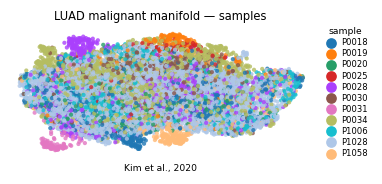

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('LUAD malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Kim et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])